# 54 · SARSA와 Q-learning: 행동한 정책과 평가할 정책

📎 **이번 질문** · 실수할 가능성이 남아 있는 배달 정책과, 탐색을 끈 배포 정책은 같은 가치를 가질까요?

시작에서 안전 경로와 위험 경로 중 하나를 선택합니다. 두 전이 뒤 반드시 종료하는 작은 환경에서 Q를 실제로 학습하고, **탐색을 유지한 행동정책**과 **탐색을 끈 배포정책**을 각각 평가합니다. 표 하나의 다른 타깃에서 출발하므로 신경망 없이 차이를 볼 수 있습니다.

- 준비물: [51 Bandit](51_bandits.ipynb), [52 Bellman](52_mdp_bellman.ipynb), [53 MC·TD](53_mc_td.ipynb).
- 도착점: SARSA·Expected SARSA·Q-learning, 행동/타깃 정책, importance ratio의 역할과 별도 평가를 연결합니다.
- NumPy·CPU만 사용합니다. 이 환경은 교재의 큰 cliff grid를 재현한 것이 아니라 같은 질문을 정확히 열거하는 축소 예제입니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·구현 | 다음 행동을 누가 고르는지 적습니다 |
| 🔍 확인 | 그림·검산 | 정확한 항등식과 학습 관측을 나눕니다 |
| 📎 참고 | 용어·코드 | 낯선 규약을 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 작은 독립 답과 비교합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. SARSA는 실제 다음 행동을, Expected SARSA는 그 행동분포를, Q-learning은 최대 Q를 타깃에 씁니다.
2. importance ratio는 표본을 낸 분포를 다른 목표 분포로 바꿔 평균할 때 등장합니다. Q-learning의 한 단계 max 타깃에 무조건 곱하는 항이 아닙니다.
3. 학습 중 받은 return, 탐색을 유지한 고정 정책 가치, 탐색을 끈 배포 가치가 서로 다릅니다.

| 기호 | shape | 뜻 |
|---|---|---|
| next,r,Q | `(S,A)` | 다음 상태·즉시 보상·상태별 행동 가치 |
| μ,π | `(S,A)` | 표본을 내는 정책·평가하려는 정책의 행동 확률 |
| uniform | `(episode,2)` | 두 행동 선택에 쓰는 균등 난수 |
| 가치 기록 | `(방법,seed,checkpoint,평가규약)` | 동결 정책의 정확 시작 가치 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/control_plots.py)

In [1]:
# 준비 셀: 계산·그림·연습 검사 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots, run_check
from src.utils.control_plots import (
    plot_control_environment, plot_sarsa_targets, plot_q_target_comparison,
    plot_importance_paths, plot_control_protocol, plot_control_learning, plot_control_final,
)
setup_plots()
print('4상태·2행동 · 항상2전이 후 진짜 종료 · 표 기반 제어')

4상태·2행동 · 항상2전이 후 진짜 종료 · 표 기반 제어


## 🔑 1. Q 표에서 실제 행동정책을 만듭니다

**이 절에서 가져갈 것:** Q는 보상 합의 추정이고 행동 확률은 별도 배열이며, 탐색은 다음 경로의 실제 결과를 바꿉니다.

안전 경로는 어느 행동을 해도 .7을 받습니다. 위험 경로는 좋은 행동이면 2, 실수 행동이면 −14를 받습니다. 시작의 즉시 보상은 0이고 γ=.9입니다.

| 상태 | 행동0 | 행동1 |
|---|---|---|
| 시작0 | 안전2로 이동·보상0 | 위험1로 이동·보상0 |
| 위험1 | 종료3·보상2 | 종료3·보상−14 |
| 안전2 | 종료3·보상.7 | 종료3·보상.7 |
| 종료3 | 종료 유지·보상0 | 종료 유지·보상0 |

> **용어**
>
> - **Q(s,a)**는 상태 s에서 행동 a를 한 뒤의 할인 보상 합 기대값입니다. 어떤 후속 정책을 따르는지도 정의의 일부입니다.
> - **행동정책(behavior policy) μ**는 실제 데이터를 모을 행동 확률입니다. 이번에는 ε-greedy입니다.
> - **제어(control)**는 고정 정책의 가치를 예측하는 데서 더 나아가, 배운 Q로 다음 행동을 바꾸는 일입니다.

최대 Q를 가진 행동 집합을 M(s)라 하면
$$\mu(a|s)=\frac\epsilon A+(1-\epsilon)\frac{\mathbf1[a\in M(s)]}{|M(s)|}.$$
동점이면 최대 행동에 균등하게 분배합니다. 위험 상태 Q=(2,−14), ε=.2이면 μ=(.9,.1)이고, 실제 기대 다음 보상은 $.9\times2+.1\times(-14)=.4$입니다. max Q=2와 다릅니다.

> **코드** · `keepdims=True`는 행동 축을 합치거나 최대를 구한 뒤 길이1로 유지합니다. `np.cumsum(p)`는 누적 확률, `np.searchsorted(...,u,side='right')`는 균등수 u가 들어간 구간의 행동 번호입니다. `np.linalg.solve(A,b)`는 Av=b를 풉니다.

In [2]:
gamma,epsilon = 0.9,0.2
example_next = np.array([[2,1],[3,3],[3,3],[3,3]])
example_reward = np.array([[0.,0.],[2.,-14.],[.7,.7],[0.,0.]])
example_policy = np.array([[.9,.1],[.9,.1],[.5,.5],[.5,.5]])
expected_loop = 0.0
for action in range(2):
    expected_loop += example_policy[1,action]*example_reward[1,action]
expected_vector = example_policy[1] @ example_reward[1]
print('위험 상태: 손계산 .4 / 반복문 / 벡터화:',expected_loop,expected_vector)

위험 상태: 손계산 .4 / 반복문 / 벡터화: 0.3999999999999999 0.3999999999999999


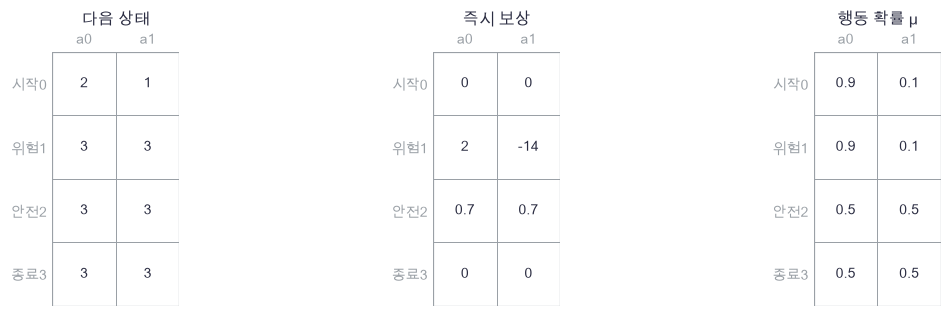

In [3]:
plot_control_environment(example_next, example_reward, example_policy)

🔍 **확인** · 상태와 행동 축을 구분해 읽습니다. 안전 상태의 두 행동은 같은 결과라서 탐색해도 보상이 달라지지 않지만, 위험 상태의 탐색은 큰 비용을 만들 수 있습니다. 환경 표의 정확한 수는 평가·검산에만 쓰고 학습은 선택한 전이의 보상만 받습니다.

In [4]:
def make_control_environment():
    """4상태·2행동의 결정적 경로. next,reward:(S,A), terminal:(S,); 항상 두 전이 후 종료."""
    next_state = np.array([[2,1],[3,3],[3,3],[3,3]])
    reward = np.array([[0.0,0.0],[2.0,-14.0],[0.7,0.7],[0.0,0.0]])
    terminal = np.array([False,False,False,True])
    return next_state,reward,terminal

In [5]:
def epsilon_policy(q,epsilon):
    """Q:(S,A)에서 최대 동점에 균등한 ε-greedy 확률을 만듭니다. → policy:(S,A)."""
    greedy = (q==q.max(axis=1,keepdims=True)).astype(float)
    greedy /= greedy.sum(axis=1,keepdims=True)
    return epsilon/q.shape[1] + (1.0-epsilon)*greedy

In [6]:
def action_from_uniform(probabilities,uniform):
    """한 상태의 행동 확률과 [0,1) 균등수로 행동을 뽑습니다. probabilities:(A,)."""
    return int(np.searchsorted(np.cumsum(probabilities),uniform,side='right'))

In [7]:
def policy_value(next_state,reward,terminal,policy,gamma):
    """고정 policy의 Bellman 선형 시스템으로 정확 V:(S,)를 구합니다."""
    transition = np.zeros((len(terminal),len(terminal)))
    for state in range(len(terminal)):
        for action in range(policy.shape[1]):
            destination = next_state[state,action]
            transition[state,destination] += policy[state,action]*(1-terminal[destination])
    mean_reward = np.sum(policy*reward,axis=1)
    return np.linalg.solve(np.eye(len(terminal))-gamma*transition,mean_reward)

In [8]:
# 쓰는 것: example_next, example_policy, example_reward, expected_loop, expected_vector, gamma, make_control_environment (위 절의 정의·실행 셀)
next_state,reward,terminal = make_control_environment()
np.testing.assert_array_equal(next_state,example_next)  # 검산: 구현한 경로=직접 적은 표
np.testing.assert_allclose(reward,example_reward)  # 검산: 각 행동의 즉시 보상
np.testing.assert_allclose(epsilon_policy(np.array([[2.,-14.],[.7,.7]]),.2),[[.9,.1],[.5,.5]])  # 검산: 최대 하나·동점 모두 균등 규칙
np.testing.assert_allclose(expected_loop,expected_vector)  # 검산: 기대 보상의 반복문=내적
assert action_from_uniform(np.array([.9,.1]),.95)==1, '누적확률 .9를 넘으면 행동1입니다'
np.testing.assert_allclose(policy_value(next_state,reward,terminal,example_policy,gamma),[.603,.4,.7,0.])  # 검산: .9×(.9×.7+.1×.4)
print('정책 확률·동점·경로·정확 가치 통과')

정책 확률·동점·경로·정확 가치 통과


### ✏️ 연습 1 · 행동분포의 다음 Q 기대값

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

행동 확률을 곱해 모두 더하세요.

In [9]:
def exercise_expectation(probabilities, next_q):
    """행동분포의 다음 Q 기대값의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [10]:
def check_expectation(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.9,.1]),np.array([2.,-14.])),.4)  # 검산:1.8−1.4
    print('행동분포의 Q 평균 통과')

run_check(check_expectation,exercise_expectation,hint='max와 확률 가중평균을 구분합니다.')

☐ exercise_expectation: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: max와 확률 가중평균을 구분합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(probabilities * next_q)
```

</details>

## 🔑 2. SARSA는 실제로 할 다음 행동을 사용합니다

**이 절에서 가져갈 것:** SARSA의 표본 타깃을 행동 확률로 평균하면 Expected SARSA 타깃이 됩니다.

시작에서 위험 경로로 이동했습니다. 바로 다음에 행동0을 할 수도 있고, 탐색으로 행동1을 할 수도 있습니다. 학습 타깃도 그 실제 다음 행동을 따라갑니다.

> **용어**
>
> - **SARSA**는 `(S,A,R,S',A')`의 다섯 항으로 갱신하는 방법입니다. A′는 다음 전이에서 실제 실행할 행동입니다.
> - **Expected SARSA**는 다음 행동 표본 대신 현재 행동정책의 Q 가중평균을 씁니다.
> - **on-policy**는 데이터를 모으는 정책의 후속 행동을 타깃에도 반영한다는 뜻입니다. 학습 중 그 정책은 Q와 함께 바뀝니다.

$$Y^{S}=R+\gamma(1-terminated)Q(S',A'),\quad A'\sim\mu(\cdot|S'),$$
$$Y^{ES}=R+\gamma(1-terminated)\sum_a\mu(a|S')Q(S',a).$$
Q와 μ를 고정하면 $E_{A'\sim\mu}[Y^S]=Y^{ES}$입니다. 위험 상태로 들어가는 전이에서 두 표본 타깃은 1.8과 −12.6이고, 그 기대값은 .36입니다. 이 기대값 일치는 고정 Q의 **한 타깃**에 관한 식이며, 두 학습 실행이 매번 같은 Q를 갖는다는 뜻은 아닙니다.

In [11]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
next_q = np.array([2.0,-14.0])
next_probabilities = np.array([0.9,0.1])
sarsa_targets = gamma*next_q
expected_target = np.sum(next_probabilities*sarsa_targets)
print('표본 타깃:',sarsa_targets,'· 기대 타깃:',expected_target)

표본 타깃: [  1.8 -12.6] · 기대 타깃: 0.3600000000000001


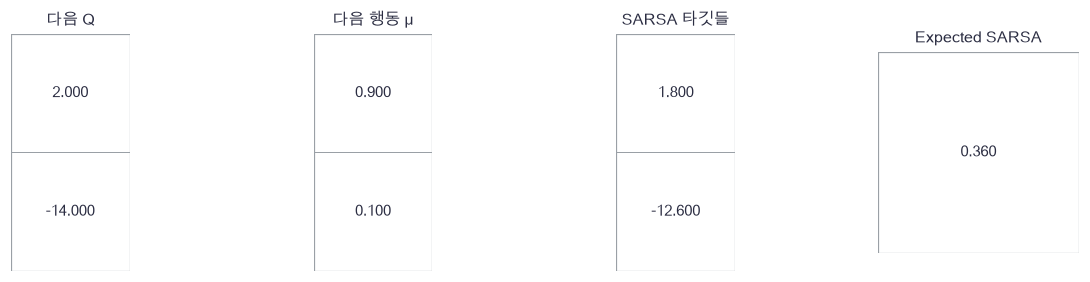

In [12]:
plot_sarsa_targets(next_q, next_probabilities, sarsa_targets, np.array([expected_target]))

🔍 **확인** · Expected SARSA는 주어진 다음 상태에서 행동 선택의 변동을 평균합니다. 전이·보상 자체가 확률적이면 그 변동은 남습니다. 이번 환경의 전이는 결정적이어서 그 구분을 쉽게 볼 수 있습니다. SARSA의 A′는 현재 Q 갱신 전에 뽑아 다음 행동으로 보존합니다.

In [13]:
def control_target(reward,next_q,terminated,method,epsilon,gamma,next_action=0):
    """갱신 전 다음 Q:(A,)에서 SARSA·Expected SARSA·Q-learning 타깃 숫자를 만듭니다."""
    # 쓰는 것: epsilon_policy (위 절의 정의·실행 셀)
    if terminated:
        return float(reward)
    if method=='SARSA':
        continuation = next_q[next_action]
    elif method=='Expected SARSA':
        probabilities = epsilon_policy(next_q[None,:],epsilon)[0]
        continuation = np.sum(probabilities*next_q)
    elif method=='Q-learning':
        continuation = np.max(next_q)
    else:
        raise ValueError('알 수 없는 제어 방법입니다')
    return float(reward+gamma*continuation)

In [14]:
# 쓰는 것: epsilon, gamma (위 절의 정의·실행 셀)
sample_targets = np.zeros(2)
for action in range(2):
    sample_targets[action] = control_target(0.0,next_q,False,'SARSA',epsilon,gamma,action)
np.testing.assert_allclose(sample_targets,[1.8,-12.6])  # 검산: 실제 다음 행동 두 경우
np.testing.assert_allclose(next_probabilities@sample_targets,control_target(0.,next_q,False,'Expected SARSA',epsilon,gamma))  # 검산: 전수 평균=Expected SARSA
for method in ['SARSA','Expected SARSA','Q-learning']:
    np.testing.assert_allclose(control_target(2.,np.array([99.,99.]),True,method,epsilon,gamma),2.0)  # 검산: 진짜 종료는 다음Q99 차단·보상2 유지
np.testing.assert_allclose(control_target(0.,next_q,False,'SARSA',epsilon,gamma,0),1.8)  # 검산: 외부 수집 제한이면 비종료 bootstrap 유지
print('SARSA 표본·기대값·종료/수집 제한 통과')

SARSA 표본·기대값·종료/수집 제한 통과


### ✏️ 연습 2 · 실제로 고른 다음 행동 타깃

비종료 전이에서 next_action 위치의 Q를 사용하세요.

In [15]:
def exercise_sarsa(reward, gamma, next_q, next_action):
    """실제로 고른 다음 행동 타깃의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [16]:
def check_sarsa(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(0.,.9,np.array([2.,-14.]),1),-12.6)  # 검산: 실제 행동1의 값 사용
    print('실제 다음 행동 타깃 통과')

run_check(check_sarsa,exercise_sarsa,hint='최대값을 고르면 다른 알고리즘입니다.')

☐ exercise_sarsa: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 최대값을 고르면 다른 알고리즘입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward + gamma * next_q[next_action]
```

</details>

## 🔑 3. Q-learning은 다음 최대 행동을 타깃에 넣습니다

**이 절에서 가져갈 것:** Q-learning은 실제 다음 탐색 행동과 별도로 max 백업을 하며, 모든 방법은 선택한 현재 칸만 갱신합니다.

위험 경로에서 이번에는 실수 행동1을 실행하더라도 Q-learning은 다음에는 최선 행동을 한다는 최대값을 시작 상태의 타깃에 씁니다.

$$Y^Q=R+\gamma(1-terminated)\max_a Q(S',a),$$
$$Q(S,A)\leftarrow Q(S,A)+\alpha[Y-Q(S,A)].$$

> **용어**
>
> - **Q-learning**은 Bellman 최적 백업의 다음 최대값으로 Q를 학습하는 방법입니다.
> - **off-policy**는 수집 정책의 다음 행동과 다른 후속 정책을 타깃으로 삼는다는 뜻입니다. Q-learning의 max는 greedy 후속 행동을 사용합니다.
> - **고정 타깃**은 현재 갱신 직전에 계산한 숫자 Y입니다. 현재 Q 칸을 바꾸는 동안 Y를 다시 계산하지 않습니다.

아래는 모두 같은 Q에서 출발한 한 번의 계산입니다. 실제 학습한 Q의 비교는 마지막 절에서 합니다. 이 작은 환경의 최적 Q는 위험 상태 `(2,−14)`, 안전 상태 `(.7,.7)`, 시작 `(.63,1.8)`입니다.

> **코드** · `np.eye(A)[actions]`는 행동 번호를 one-hot 행으로 바꿉니다. `np.max(values,axis=0)`은 정책 축을 줄여 상태별 최댓값을 남깁니다.

In [17]:
# 쓰는 것: expected_target, gamma, next_q, sarsa_targets (위 절의 정의·실행 셀)
comparison_targets = np.array([sarsa_targets[1],expected_target,gamma*np.max(next_q)])
comparison_updated = 0.2+0.1*(comparison_targets-0.2)

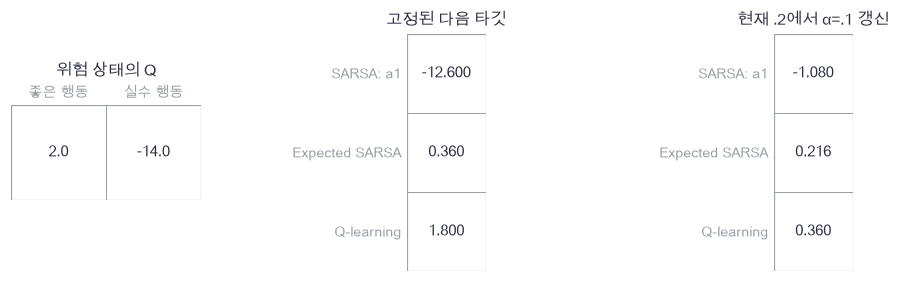

In [18]:
plot_q_target_comparison(next_q, comparison_targets, comparison_updated)

🔍 **확인** · 실수 행동을 고른 SARSA 타깃과 max를 쓰는 Q-learning 타깃은 부호까지 다릅니다. 이것은 계산 오류가 아니라 후속 정책의 차이입니다. 표 기반 Q-learning의 수렴 정리에는 충분한 방문과 적절한 학습률 등 조건이 있습니다. 이 단원의 고정 ε·고정 α·유한 예산 결과를 그 보장으로 해석하지 않습니다.

In [19]:
def optimal_q(next_state,reward,terminal,gamma):
    """이 두 전이 환경에서 Bellman 최적 백업을 세 번 합니다. → Q*:(S,A)."""
    q = np.zeros_like(reward)
    for sweep in range(3):
        q = reward+gamma*(1-terminal[next_state])*q.max(axis=1)[next_state]
    return q

In [20]:
# 쓰는 것: control_target, epsilon, gamma, next_q, next_state, policy_value, reward, terminal (위 절의 정의·실행 셀)
q_star = optimal_q(next_state,reward,terminal,gamma)
np.testing.assert_allclose(q_star,[[.63,1.8],[2.,-14.],[.7,.7],[0.,0.]])  # 검산: 마지막 보상부터 두 단계 손계산
np.testing.assert_allclose(control_target(0.,next_q,False,'Q-learning',epsilon,gamma),1.8)  # 검산: 행동 선택과 무관한 max 백업
np.testing.assert_allclose(control_target(3.,next_q,False,'Q-learning',epsilon,0.0),3.0)  # 검산: γ0이면 즉시 보상만
deterministic_values = []
for a0 in range(2):
    for a1 in range(2):
        for a2 in range(2):
            policy = np.eye(2)[np.array([a0,a1,a2,0])]
            deterministic_values.append(policy_value(next_state,reward,terminal,policy,gamma))
np.testing.assert_allclose(np.max(deterministic_values,axis=0),q_star.max(axis=1))  # 검산: 8개 결정적 정책 전수평가=최적 Q의 상태최대
print('최적 Q·정책 전수열거·gamma0 통과')

최적 Q·정책 전수열거·gamma0 통과


### ✏️ 연습 3 · max 백업

비종료 전이의 Q-learning 타깃을 구하세요.

In [21]:
def exercise_max_target(reward, gamma, next_q):
    """max 백업의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [22]:
def check_max_target(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(.2,.9,np.array([.3,.8])),.92)  # 검산:.2+.9×.8
    print('최대값 백업 통과')

run_check(check_max_target,exercise_max_target,hint='다음 행동 전체를 최댓값으로 줄입니다.')

☐ exercise_max_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 다음 행동 전체를 최댓값으로 줄입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward + gamma * np.max(next_q)
```

</details>

## 🔑 4. 다른 정책의 경로 평균에는 확률비가 필요합니다

**이 절에서 가져갈 것:** 경로를 낸 행동정책과 평가하려는 목표정책을 분리하고, importance ratio의 support 조건을 확인합니다.

이번에는 Q를 갱신하지 않고, 이미 모은 경로로 **고정된 다른 정책**의 return을 평가하려고 합니다. 시작과 두 번째 행동의 경로 확률을 곱하면 가능한 경로는 네 개입니다.

> **용어**
>
> - **목표정책(target policy) π**는 기대 return을 알고 싶은 고정 정책입니다.
> - **importance ratio**는 목표 경로 확률을 수집 경로 확률로 나눈 수입니다. 같은 환경의 전이 확률은 비율에서 소거됩니다.
> - **support 조건**은 목표가 양의 확률로 쓰는 모든 경로를 행동정책도 양의 확률로 관측할 수 있어야 한다는 조건입니다.

$$\rho(\tau)=\prod_t\frac{\pi(A_t|S_t)}{\mu(A_t|S_t)},\qquad
E_{\tau\sim\mu}[\rho(\tau)G(\tau)]=E_{\tau\sim\pi}[G(\tau)].$$

μ의 시작 확률은 `(.7,.3)`, 위험 상태는 `(.8,.2)`, 안전 상태는 `(.5,.5)`입니다. π는 시작 `(.1,.9)`, 위험 상태 `(1,0)`, 안전 상태 `(.5,.5)`입니다. 경로 순서는 안전a0·안전a1·위험a0·위험a1입니다. 작은 μ 경로 확률은 큰 비율을 만들 수 있습니다. 유한 표본에 목표 경로가 하나도 안 나오면 support가 이론상 양수여도 추정은 불안정합니다.

> **코드** · `np.column_stack`은 배열을 열로 붙입니다. `np.divide(...,out=...,where=...)`는 허용한 위치만 나눕니다. μ=π=0인 경로는 기여0으로 두지만 μ=0<π는 오류로 처리합니다. `np.eye(A)[actions]`는 행동 번호를 one-hot 행으로 바꿉니다.

In [23]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
behavior_paths = np.array([.7*.5,.7*.5,.3*.8,.3*.2])
target_paths = np.array([.1*.5,.1*.5,.9*1.,.9*0.])
path_returns = gamma*np.array([.7,.7,2.,-14.])
path_ratios = target_paths/behavior_paths
path_contributions = behavior_paths*path_ratios*path_returns
print('목표 정책의 정확 경로 평균:',np.sum(target_paths*path_returns),'· 비율 보정:',path_contributions.sum())

목표 정책의 정확 경로 평균: 1.683 · 비율 보정: 1.683


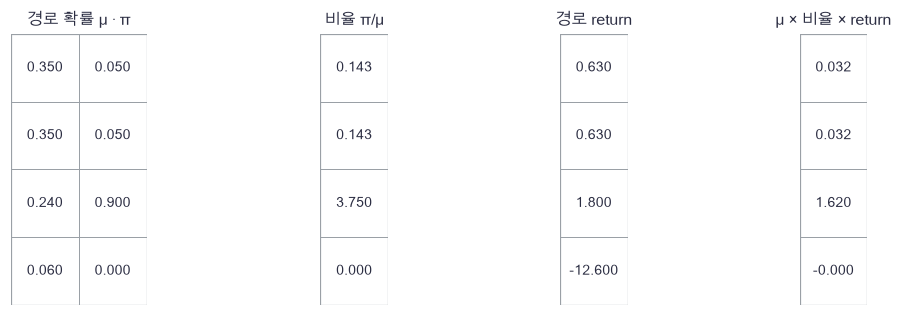

In [24]:
plot_importance_paths(np.column_stack([behavior_paths,target_paths]), path_ratios, path_returns, path_contributions)

🔍 **확인** · 목표정책은 위험 상태에서 나쁜 행동을 하지 않으므로 해당 경로의 비율과 기여는0입니다. 여기서는 ordinary importance sampling의 **정확한 전수 기대값**을 확인했습니다. 표본 추정의 분산이나 유한 표본 성능을 보장한 것은 아닙니다. Q-learning의 조건부 한 전이 `(s,a,r,s′)` max 백업은 다음 행동을 표본 평균하지 않으므로 이 경로 비율을 매번 곱하지 않습니다. 그래도 방문하지 않은 `(s,a)`의 Q를 데이터 없이 배울 수는 없습니다.

In [25]:
def weighted_policy_return(behavior,target,returns):
    """모든 경로를 열거한 IS 기대값. target>0인 경로에는 behavior>0이 필요합니다."""
    if np.any((target>0)&(behavior<=0)):
        raise ValueError('타깃 경로의 support를 행동 정책이 덮어야 합니다')
    ratios = np.divide(target,behavior,out=np.zeros_like(target),where=behavior>0)
    return float(np.sum(behavior*ratios*returns)),ratios

In [26]:
# 쓰는 것: gamma, next_state, policy_value, reward, terminal (위 절의 정의·실행 셀)
is_value,ratios = weighted_policy_return(behavior_paths,target_paths,path_returns)
target_policy = np.array([[.1,.9],[1.,0.],[.5,.5],[.5,.5]])
np.testing.assert_allclose(is_value,1.683)  # 검산:.1×.63+.9×1.8
np.testing.assert_allclose(is_value,policy_value(next_state,reward,terminal,target_policy,gamma)[0])  # 검산: 경로 IS 전수합=Bellman 선형해
np.testing.assert_allclose(ratios[2],(.9/.3)*(1./.8))  # 검산: 경로 확률비=행동 확률비의 곱
try:
    weighted_policy_return(np.array([1.,0.]),np.array([.5,.5]),np.array([0.,1.]))
except ValueError:
    print('목표 경로를 놓친 support 오류를 명시적으로 차단했습니다')
else:
    raise AssertionError('support가 없으면 계산을 거절해야 합니다')
print('정책별 확률·경로비·정확 기대값 통과')

목표 경로를 놓친 support 오류를 명시적으로 차단했습니다
정책별 확률·경로비·정확 기대값 통과


### ✏️ 연습 4 · 지원되는 행동의 확률비

두 확률이 양수인 행동의 비율을 구하세요.

In [27]:
def exercise_ratio(target_probability, behavior_probability):
    """지원되는 행동의 확률비의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return ratio

In [28]:
def check_ratio(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(.9,.3),3.0)  # 검산:목표에서3배 자주 쓰는 행동
    print('행동 확률비 통과')

run_check(check_ratio,exercise_ratio,hint='분자는 평가 목표, 분모는 데이터를 만든 정책입니다.')

☐ exercise_ratio: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 분자는 평가 목표, 분모는 데이터를 만든 정책입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ratio = target_probability / behavior_probability
```

</details>

## 🔑 5. 실제 Q 학습과 두 배포 규약을 비교합니다

**이 절에서 가져갈 것:** 같은 환경 전이 예산으로 실제 제어를 학습하고, 훈련 중 return과 두 가지 동결 정책 가치를 나눠 읽습니다.

32개 독립 seed마다 세 알고리즘을 **1,000개 episode·2,000개 전이**로 학습합니다. 초기 Q=0·γ=.9·ε=.2·α=.1을 미리 정합니다. 매 50개 episode의 Q를 복사하고, 그 Q의 ε 정책 및 ε=0 정책을 각각 정확히 평가합니다. 평가에서는 Q를 갱신하지 않습니다.

동일 seed의 방법들은 같은 행동용 균등수 표를 쓰지만, Q가 달라지면 다른 행동과 경로를 선택합니다. 따라서 **같은 전이 데이터** 비교가 아니라 같은 환경·상호작용 예산·난수 기반 비교입니다. 별도의 rollout 평가는 다른 난수로 최종 정책을 고정하여 수행합니다.

최적 Q를 그대로 읽어도 ε 정책의 시작 가치는 .387이고 greedy 배포 가치는1.8입니다. 안전 경로를 선호하는 정책은 ε 유지 .603·ε 제거 .63이 될 수 있습니다. 둘 중 무엇을 최적화하려는지 먼저 정해야 합니다.

> **코드** · `records.append(q.copy())`는 그 시점의 표를 보존합니다. `enumerate(items)`는 순서 번호와 원소를 함께 줍니다. `np.stack`은 같은 모양의 배열을 새 축으로 쌓습니다. `std(ddof=1)/sqrt(seed수)`는 독립 학습 seed 평균의 SE이며, 같은 실행 내 episode들을 독립 seed처럼 세지 않습니다.

> **코드** · `[f(e) for e in values]`는 각 e에 같은 계산을 적용해 목록을 만듭니다. `np.arange(0,T+1,k)`는 0부터 T까지 k 간격의 checkpoint 번호입니다.

In [29]:
# 쓰는 것: epsilon, epsilon_policy, gamma, next_state, policy_value, q_star, reward, terminal (위 절의 정의·실행 셀)
REPEATS,EPISODES,INTERVAL = 32,1000,50
alpha = 0.1
protocol_settings = np.array([[REPEATS],[EPISODES],[2],[epsilon],[alpha]])
protocol_policies = np.stack([epsilon_policy(q_star,epsilon)[0],epsilon_policy(q_star,0.0)[0]])
protocol_values = np.array([policy_value(next_state,reward,terminal,epsilon_policy(q_star,e),gamma)[0] for e in [epsilon,0.0]])

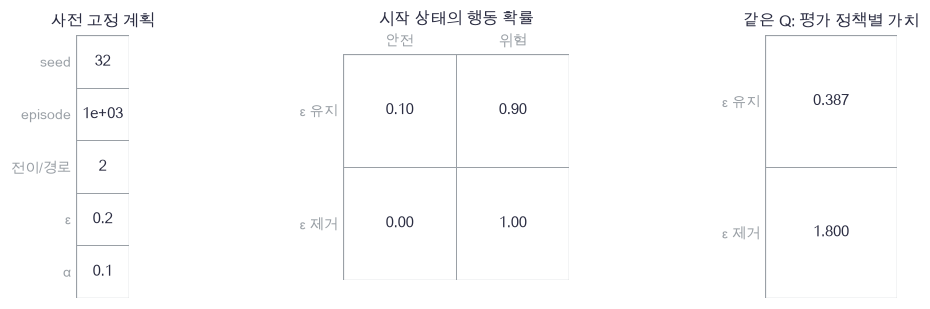

In [30]:
plot_control_protocol(protocol_settings, protocol_policies, protocol_values)

🔍 **확인** · 최적 Q 자체가 같아도 평가에서 탐색을 유지하면 실수 비용을 포함합니다. 마지막 두 평가 열을 서로 다른 목적의 지표로 읽습니다. 학습이 끝나고 마음에 드는 평가 규약으로 바꿔 우열을 주장하지 않습니다.

In [31]:
def train_control(next_state,reward,terminal,uniforms,method,epsilon,gamma,alpha=0.1,interval=50):
    """주어진 행동 난수로 실제 TD 제어를 학습합니다. uniforms:(episode,2), 반환 Q·checkpoint·return."""
    # 쓰는 것: action_from_uniform, control_target, epsilon_policy (위 절의 정의·실행 셀)
    # 1. 같은 0 초기값과 고정 α; 각 경로는 두 전이입니다.
    q = np.zeros_like(reward)
    records = [q.copy()]
    returns = np.zeros(len(uniforms))
    for episode in range(len(uniforms)):
        state = 0
        policy = epsilon_policy(q,epsilon)
        action = action_from_uniform(policy[state],uniforms[episode,0])
        for step in range(2):
            destination = next_state[state,action]
            observed_reward = reward[state,action]
            done = bool(terminal[destination])
            # 2. SARSA의 실제 다음 행동은 현재 갱신 전에 뽑아 그대로 실행합니다.
            next_action = 0
            if not done:
                probabilities = epsilon_policy(q[destination:destination+1],epsilon)[0]
                next_action = action_from_uniform(probabilities,uniforms[episode,step+1])
            target = control_target(observed_reward,q[destination],done,method,epsilon,gamma,next_action)
            q[state,action] += alpha*(target-q[state,action])
            returns[episode] += gamma**step*observed_reward
            state,action = destination,next_action
            if done:
                break
        # 3. 스냅샷은 복사해서 나중 갱신과 분리합니다.
        if (episode+1)%interval==0:
            records.append(q.copy())
    return q,np.array(records),returns

In [32]:
def evaluate_control_records(records,next_state,reward,terminal,epsilon,gamma):
    """학습 기록마다 동결 행동정책(ε 유지)과 배포정책(ε=0)의 정확 시작 가치를 계산합니다."""
    # 쓰는 것: epsilon_policy, policy_value (위 절의 정의·실행 셀)
    values = np.zeros((len(records),2))
    for index,q in enumerate(records):
        for mode,parameter in enumerate([epsilon,0.0]):
            policy = epsilon_policy(q,parameter)
            values[index,mode] = policy_value(next_state,reward,terminal,policy,gamma)[0]
    return values

In [33]:
# 쓰는 것: epsilon, gamma, next_state, reward, terminal (위 절의 정의·실행 셀)
single_uniforms = np.array([[.75,.95]])
single_q,single_records,single_return = train_control(next_state,reward,terminal,single_uniforms,'SARSA',epsilon,gamma,alpha=1.,interval=1)
np.testing.assert_allclose(single_q[1],[0.,-14.])  # 검산: 선택한 위험 행동1만 즉시 보상으로 갱신
np.testing.assert_allclose(single_return,[-12.6])  # 검산: 종료 경로0+.9×(−14)
np.testing.assert_allclose(single_records[0],0.)  # 검산: 최초 Q의 복사본은 보존
np.testing.assert_allclose(single_q[3],0.)  # 검산: 종료 Q는 갱신하지 않음
print('실제 행동·선택한 칸·종료·스냅샷 보존 통과')

실제 행동·선택한 칸·종료·스냅샷 보존 통과


In [34]:
# 쓰는 것: EPISODES, INTERVAL, REPEATS, alpha, epsilon, gamma, next_state, reward, terminal (위 절의 정의·실행 셀)
methods = ['SARSA','Expected SARSA','Q-learning']
checkpoints = np.arange(0,EPISODES+1,INTERVAL)
value_records = np.zeros((3,REPEATS,len(checkpoints),2))
final_tables = np.zeros((3,REPEATS,4,2))
observed_returns = np.zeros((3,REPEATS))
for repeat in range(REPEATS):
    uniforms = np.random.default_rng(54100+repeat).random((EPISODES,2))
    for method_index,method in enumerate(methods):
        learned_q,records,returns = train_control(next_state,reward,terminal,uniforms,method,epsilon,gamma,alpha,INTERVAL)
        final_tables[method_index,repeat] = learned_q
        observed_returns[method_index,repeat] = returns.mean()
        value_records[method_index,repeat] = evaluate_control_records(records,next_state,reward,terminal,epsilon,gamma)
print('실제 학습 완료:3방법×32seed×1000episode·각2전이')

실제 학습 완료:3방법×32seed×1000episode·각2전이


In [35]:
# 쓰는 것: REPEATS (위 절의 정의·실행 셀)
mean_values = value_records.mean(axis=1)
se_values = value_records.std(axis=1,ddof=1)/np.sqrt(REPEATS)
final_values = value_records[:,:,-1,:]

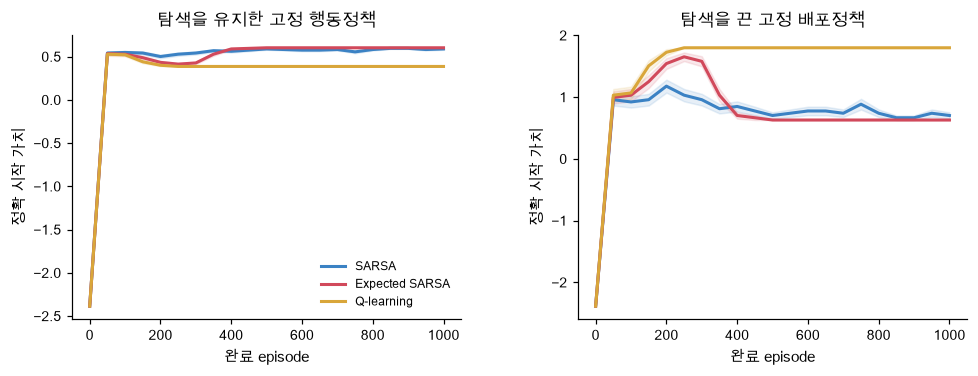

In [36]:
plot_control_learning(checkpoints, mean_values, se_values, methods)

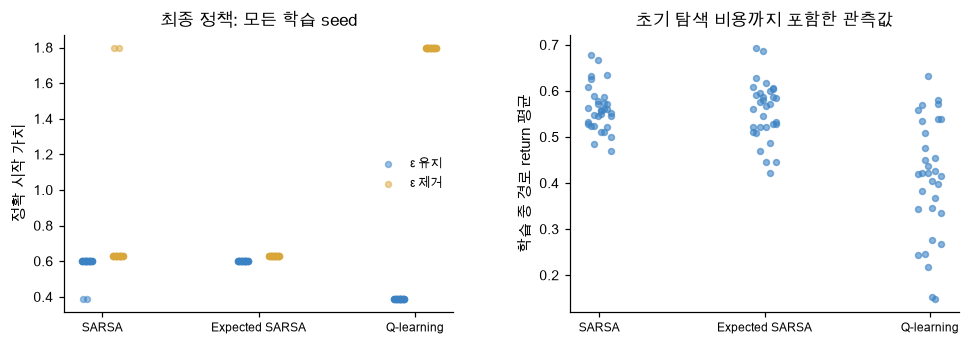

In [37]:
plot_control_final(methods, final_values, observed_returns)

🔍 **확인** · 띠는 독립 학습 seed 평균의 SE이며 곡선 전체의 동시 신뢰구간은 아닙니다. 최종 그림에는 모든 seed를 남겼습니다. 같은 return 축이어도 학습 중 변화하는 정책의 평균과 마지막에 고정한 정책의 가치는 다른 대상입니다. 고정 α 때문에 SARSA의 표본 타깃은 계속 흔들릴 수 있고, 이 한 환경의 결과를 보편적 알고리즘 순위로 확장하지 않습니다.

In [38]:
# 쓰는 것: action_from_uniform, epsilon, epsilon_policy, final_tables, gamma, methods, next_state, reward (위 절의 정의·실행 셀)
evaluation_uniforms = np.random.default_rng(54999).random((2000,2))
for method_index,method in enumerate(methods):
    frozen = final_tables[method_index,0]
    policy = epsilon_policy(frozen,epsilon)
    evaluation_returns = np.zeros(len(evaluation_uniforms))
    for episode in range(len(evaluation_uniforms)):
        state = 0
        for step in range(2):
            action = action_from_uniform(policy[state],evaluation_uniforms[episode,step])
            evaluation_returns[episode] += gamma**step*reward[state,action]
            state = next_state[state,action]
    print(method,'32seed 최종 가치 평균 [ε유지,ε제거]:',np.round(final_values[method_index].mean(axis=0),4))
    print('첫seed 별도2000경로 평가 평균/SE/정확값:',round(evaluation_returns.mean(),4),round(evaluation_returns.std(ddof=1)/np.sqrt(2000),4),round(final_values[method_index,0,0],4))
np.testing.assert_allclose(final_tables[:,:,3,:],0.0)  # 검산: 실제 학습에서도 종료 Q=0 유지
assert np.isfinite(final_tables).all(), '학습된 모든 Q는 유한해야 합니다'
print('종료 Q·유한값 통과 · 성능 우열의 확률적 assert는 하지 않습니다')

SARSA 32seed 최종 가치 평균 [ε유지,ε제거]: [0.5895 0.7031]
첫seed 별도2000경로 평가 평균/SE/정확값: 0.5932 0.0297 0.603
Expected SARSA 32seed 최종 가치 평균 [ε유지,ε제거]: [0.603 0.63 ]
첫seed 별도2000경로 평가 평균/SE/정확값: 0.5932 0.0297 0.603
Q-learning 32seed 최종 가치 평균 [ε유지,ε제거]: [0.387 1.8  ]
첫seed 별도2000경로 평가 평균/SE/정확값: 0.5473 0.0862 0.387
종료 Q·유한값 통과 · 성능 우열의 확률적 assert는 하지 않습니다


### ✏️ 연습 5 · 선택한 Q 칸 갱신

한 타깃을 고정하고 현재 Q를 이동하세요.

In [39]:
def exercise_update(prediction, target, alpha):
    """선택한 Q 칸 갱신의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return updated

In [40]:
def check_update(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(.2,1.8,.1),.36)  # 검산:.2+.1×1.6
    print('선택한 Q 갱신 통과')

run_check(check_update,exercise_update,hint='타깃 자체를 다시 계산하지 않습니다.')

☐ exercise_update: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 타깃 자체를 다시 계산하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = prediction + alpha * (target - prediction)
```

</details>

## ✏️ 전체 연결 연습 A–D

종료 경계·동점·경로 확률·평가 정책을 작은 식으로 확인합니다.

### ✏️ 연습 A · 종료에서 다음 가치 차단

terminated가 True면 다음 값만 없애세요.

In [41]:
def exercise_terminal(reward, gamma, continuation, terminated):
    """종료에서 다음 가치 차단의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return target

In [42]:
def check_terminal(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(2.,.9,99.,True),2.)  # 검산:종료 보상은남고 다음값은차단
    print('종료 마스크 통과')

run_check(check_terminal,exercise_terminal,hint='보상까지0으로 만들면 안 됩니다.')

☐ exercise_terminal: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 보상까지0으로 만들면 안 됩니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
target = reward + gamma * (1 - float(terminated)) * continuation
```

</details>

### ✏️ 연습 B · 모든 행동이 동점일 때

A개 행동 모두가 최대일 때 정책을 반환하세요.

In [43]:
def exercise_tie(actions, epsilon):
    """모든 행동이 동점일 때의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return probabilities

In [44]:
def check_tie(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(3,.2),[1/3,1/3,1/3])  # 검산:탐색과greedy모두균등
    print('동점 균등 통과')

run_check(check_tie,exercise_tie,hint='epsilon에 관계없이 모든 행동이 대칭입니다.')

☐ exercise_tie: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: epsilon에 관계없이 모든 행동이 대칭입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
probabilities = np.full(actions, 1.0 / actions)
```

</details>

### ✏️ 연습 C · 두 행동의 경로 비율

각 시점 비율의 곱을 구하세요.

In [45]:
def exercise_path_ratio(target, behavior):
    """두 행동의 경로 비율의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return ratio

In [46]:
def check_path_ratio(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.9,1.]),np.array([.3,.8])),3.75)  # 검산:3×1.25
    print('경로 확률비 통과')

run_check(check_path_ratio,exercise_path_ratio,hint='이번 입력의 모든 behavior 확률은 양수입니다.')

☐ exercise_path_ratio: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이번 입력의 모든 behavior 확률은 양수입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ratio = np.prod(target / behavior)
```

</details>

### ✏️ 연습 D · 배포 확률이 바뀐 기대 가치

시작 행동 확률과 각 경로 가치를 내적하세요.

In [47]:
def exercise_deployment(probabilities, branch_values):
    """배포 확률이 바뀐 기대 가치의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [48]:
def check_deployment(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.1,.9]),np.array([.63,1.8])),1.683)  # 검산:.063+1.62
    print('배포 정책 기대값 통과')

run_check(check_deployment,exercise_deployment,hint='정책을 바꾸면 같은 경로 가치에서도 평균이 달라집니다.')

☐ exercise_deployment: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정책을 바꾸면 같은 경로 가치에서도 평균이 달라집니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(probabilities * branch_values)
```

</details>

## ✏️ 준비도: 네 가지로 확인합니다

- **설명:** SARSA가 실제 A′를 보존해야 하는 이유와 Q-learning이 그 A′를 타깃에서 쓰지 않는 이유를 말할 수 있나요?
- **수식:** 고정 Q에서 SARSA 타깃의 행동 기대값을 계산해 Expected SARSA 식을 얻을 수 있나요?
- **구현:** 종료는 bootstrap을 막고 수집 제한은 유지하며, 갱신한 Q가 과거 스냅샷을 바꾸지 않게 만들 수 있나요?
- **변형 검산:** ε를0으로 바꾸거나 위험 보상을 바꿨을 때 두 배포 규약의 정확 가치를 먼저 구하고 학습 결과와 비교할 수 있나요?

## 📎 참고: 읽을 거리와 다음 연결

- Sutton·Barto, [Reinforcement Learning: An Introduction 공식 책 안내](http://incompleteideas.net/book/the-book-2nd.html), 5–6장의 off-policy 평가와 TD 제어를 확장 읽기로 연결합니다. 이 예제의 식은 본문 손계산·정책 전수열거로 검산했습니다.
- [Gymnasium 공식 종료·수집 제한 설명](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/): 진짜 종료는 bootstrap을 막지만 외부 수집 제한은 다음 가치를 남기는 규약을 확인할 수 있습니다. 실행에 Gymnasium은 필요 없습니다.
- 다음 55번에서는 표 Q를 신경망으로 바꿀 때 생기는 replay·타깃 고정·미분 분리를 다룹니다. 이번 표 기반 갱신에는 신경망 backward나 optimizer 상태가 필요하지 않습니다. [전체 학습 경로](../../docs/CURRICULUM.md)에서 연결을 확인하세요.